# Track 1 — Q1.3, Q1.5: Post-hoc Calibration vs. End-to-End (Figure 1-F, Table 1-B)

**Experiment Plan reference:** Track 1, Figure 1-F, Table 1-B.

**Experiment questions answered in this notebook:**

> **Q1.3.** How do different post-hoc calibration methods (temperature scaling, Platt scaling, isotonic regression, histogram binning) compare to each other and to the end-to-end calibrated baseline, across model complexities?
>
> **Q1.5.** Does post-hoc calibration degrade for overparameterised models, and if so, at what capacity level does the degradation become apparent?

**Scope decisions:**

1. **Full capacity grid, not just the primary three.** Q1.5 explicitly asks *"at what capacity level"* degradation appears — that's only answerable with more than three points, the same reasoning that justified using the full grid for Notebook 1's Figure 1-A. So this notebook uses all of `{5, 10, 100, 120, 200, 300, 1000}`.
2. **A genuine train/calibration split, not a relabeling.** §1.6 specifies post-hoc methods are fit on *"a held-out calibration set (20% of training data)"*. With $n_{\text{train}}=100$, that's 20 points for calibration and only 80 for actually fitting the baseline model — a real methodological change from every previous notebook, which trained on the full 100. Implemented as a fixed, reproducible 80/20 split of the same 100 points (not a fresh draw).
3. **The end-to-end comparison model is trained on the full $n=100$.** This is deliberate, not an oversight: the practical point of end-to-end calibration is that it doesn't need to sacrifice training data to a calibration holdout, while every post-hoc method does. Using 80 points for post-hoc's baseline and 100 for end-to-end reflects that real trade-off rather than artificially equalizing it away. The end-to-end model uses $\lambda=0.1$, the value Notebook 3 found near-optimal for MSE$_\eta$ across all three primary capacities.
4. **Five-seed main sweep.** The main comparison is repeated for five paired data and initialization seeds. Figures show the mean test ECE across seeds; Table 1-B reports mean ± sample standard deviation. Section 4 remains a separate 10-split sensitivity check at $m=1000$.

## 0. Setup

In [1]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)


def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))


def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y


def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)


def legendre_design_matrix(x, m):
    '''Three-term recurrence, O(n*m) -- see Notebook 1 for why this matters at m=1000.'''
    x = np.asarray(x, dtype=np.float64)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)


def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
import track1_core as t1

torch.set_default_dtype(torch.float64)

PALETTE_METHOD = {
    "raw": "#adb5bd",
    "temp_scaling": "#2a9d8f",
    "platt": "#e9c46a",
    "isotonic": "#f4a261",
    "histogram": "#e76f51",
    "end_to_end": "#264653",
}

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

DATA_SEED = 1
INIT_SEED = 42
SPLIT_SEED = 123     # seed for the 80/20 train/calibration split
N_SEEDS = 5
SEED_OFFSETS = [0, 1, 2, 3, 4]

DATA_SEEDS = []
INIT_SEEDS = []

for seed_offset in SEED_OFFSETS:
    DATA_SEEDS.append(DATA_SEED + 100 * seed_offset)
    INIT_SEEDS.append(INIT_SEED + 100 * seed_offset)

SEED_PAIRS = list(zip(DATA_SEEDS, INIT_SEEDS))
E2E_LAMBDA = 0.1     # near-optimal per Notebook 3
EPOCHS = 1200

## 1. Post-hoc calibration methods

All four fit on $(z_{\text{calib}}, y_{\text{calib}})$ (logits for temperature/Platt scaling,
probabilities for isotonic/histogram binning) and are applied to test-set predictions.


In [3]:
def logit(p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def fit_temperature_scaling(z_calib, y_calib):
    '''Single scalar T minimizing NLL of sigmoid(z/T) on the calibration set. Optimize in
    log-space so T > 0 is automatic.'''
    def nll(logT):
        T = np.exp(logT)
        p = np.clip(t1.sigmoid(z_calib / T), 1e-12, 1 - 1e-12)
        return -np.mean(y_calib * np.log(p) + (1 - y_calib) * np.log(1 - p))
    res = minimize_scalar(nll, bounds=(-3, 3), method="bounded")
    return np.exp(res.x)


def fit_platt_scaling(z_calib, y_calib):
    '''Two-parameter sigmoid(a*z+b) via near-unregularized 1D logistic regression.'''
    lr = LogisticRegression(C=1e6, solver="lbfgs")
    lr.fit(z_calib.reshape(-1, 1), y_calib)
    return lr.coef_[0, 0], lr.intercept_[0]


def fit_isotonic_regression(p_calib, y_calib):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
    iso.fit(p_calib, y_calib)
    return iso


def fit_histogram_binning(p_calib, y_calib, B=15):
    '''15 equal-width bins (per plan); calibrated p = empirical rate in that bin. With only
    n_calib=20 points across 15 bins, many bins will be sparse or empty -- empty bins fall back
    to the nearest non-empty bin's rate rather than crashing.'''
    edges = np.linspace(0.0, 1.0, B + 1)
    bin_idx_calib = np.clip(np.digitize(p_calib, edges[1:-1], right=False), 0, B - 1)
    bin_rate = np.full(B, np.nan)
    for b in range(B):
        mask = bin_idx_calib == b
        if mask.sum() > 0:
            bin_rate[b] = y_calib[mask].mean()
    if np.any(np.isnan(bin_rate)):
        valid_idx = np.where(~np.isnan(bin_rate))[0]
        if len(valid_idx) > 0:
            for b in np.where(np.isnan(bin_rate))[0]:
                bin_rate[b] = bin_rate[valid_idx[np.argmin(np.abs(valid_idx - b))]]
        else:
            bin_rate[:] = y_calib.mean()
    return edges, bin_rate


def apply_temperature_scaling(z, T):
    return t1.sigmoid(z / T)

def apply_platt_scaling(z, a, b):
    return t1.sigmoid(a * z + b)

def apply_isotonic_regression(p, iso):
    return iso.predict(p)

def apply_histogram_binning(p, edges, bin_rate):
    bin_idx = np.clip(np.digitize(p, edges[1:-1], right=False), 0, len(bin_rate) - 1)
    return bin_rate[bin_idx]


def top_label_ece(p, y, B=10):
    p = np.asarray(p, dtype=np.float64); y = np.asarray(y, dtype=np.float64)
    n = len(p)
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(np.float64) == y).astype(np.float64)
    edges = np.linspace(0.5, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(conf, edges[1:-1], right=False), 0, B - 1)
    ece = 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        ece += (n_b / n) * abs(correct[mask].mean() - conf[mask].mean())
    return ece

### Sanity checks

1. On a large synthetic calibration set ($n=200$), all four methods should reduce ECE relative to
   a deliberately overconfident, uncalibrated baseline.
2. Fitted temperature should correctly recover $T>1$ when the synthetic logits were
   over-scaled.


In [4]:
rng = np.random.default_rng(0)
n_calib_test, n_test = 200, 50_000

p_true_calib = rng.uniform(0.05, 0.95, n_calib_test)
y_calib_synth = rng.binomial(1, p_true_calib)
z_calib_overconf = 2.5 * logit(p_true_calib)   # over-scaled logits -> overconfident

p_true_test = rng.uniform(0.05, 0.95, n_test)
y_test_synth = rng.binomial(1, p_true_test)
z_test_overconf = 2.5 * logit(p_true_test)
p_test_overconf = t1.sigmoid(z_test_overconf)

ece_before = top_label_ece(p_test_overconf, y_test_synth)
print(f"ECE before calibration: {ece_before:.5f}")

T = fit_temperature_scaling(z_calib_overconf, y_calib_synth)
ece_ts = top_label_ece(apply_temperature_scaling(z_test_overconf, T), y_test_synth)
print(f"fitted T={T:.3f} (should be > 1): ECE after TS = {ece_ts:.5f}")
assert T > 1.5 and ece_ts < ece_before

a, b = fit_platt_scaling(z_calib_overconf, y_calib_synth)
ece_platt = top_label_ece(apply_platt_scaling(z_test_overconf, a, b), y_test_synth)
print(f"Platt (a={a:.3f}, b={b:.3f}): ECE = {ece_platt:.5f}")
assert ece_platt < ece_before

p_calib_overconf = t1.sigmoid(z_calib_overconf)
iso = fit_isotonic_regression(p_calib_overconf, y_calib_synth)
ece_iso = top_label_ece(apply_isotonic_regression(p_test_overconf, iso), y_test_synth)
print(f"Isotonic: ECE = {ece_iso:.5f}")
assert ece_iso < ece_before

edges, bin_rate = fit_histogram_binning(p_calib_overconf, y_calib_synth, B=15)
ece_hist = top_label_ece(apply_histogram_binning(p_test_overconf, edges, bin_rate), y_test_synth)
print(f"Histogram binning: ECE = {ece_hist:.5f}")
assert ece_hist < ece_before

print("\nOK: all four post-hoc methods reduce ECE given a reasonably sized calibration set.")

ECE before calibration: 0.13265
fitted T=2.423 (should be > 1): ECE after TS = 0.00660
Platt (a=0.413, b=-0.008): ECE = 0.00754
Isotonic: ECE = 0.05886
Histogram binning: ECE = 0.08895

OK: all four post-hoc methods reduce ECE given a reasonably sized calibration set.


## 2. Train/calibration split, and baseline + end-to-end training

Reproducible 80/20 split of the same 100 training points used everywhere else in Track 1.


In [5]:
def split_train_calib(X, Y, seed, frac_calib=0.2):
    n = len(X)
    perm = np.random.default_rng(seed).permutation(n)
    n_calib = int(round(n * frac_calib))
    calib_idx, train_idx = perm[:n_calib], perm[n_calib:]
    return X[train_idx], Y[train_idx], X[calib_idx], Y[calib_idx]


X_full, Y_full = t1.generate_data(n=100, seed=DATA_SEED)
X_tr80, Y_tr80, X_calib, Y_calib = split_train_calib(X_full, Y_full, seed=SPLIT_SEED)
print(f"train subset: n={len(X_tr80)}, positive rate={Y_tr80.mean():.3f}")
print(f"calibration subset: n={len(X_calib)}, positive rate={Y_calib.mean():.3f}")

train subset: n=80, positive rate=0.512
calibration subset: n=20, positive rate=0.450


In [6]:
def soft_ece_penalty(p, y, B=15, h=0.08):
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    w = torch.softmax(-(p.unsqueeze(1) - centers.unsqueeze(0)) ** 2 / (2 * h ** 2), dim=1)
    w_sg = w.detach()
    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()


def base_loss_fn(p, y, kind):
    eps = 1e-12
    if kind == "ce":
        p_c = p.clamp(eps, 1 - eps)
        return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()
    elif kind == "brier":
        return ((p - y) ** 2).mean()
    else:
        raise ValueError(kind)


def train_final_theta(X_tr, Y_tr, m, init_seed, lam, base_loss="ce", lr=0.5, epochs=EPOCHS):
    '''Full-batch GD, returns only the final theta (no snapshots needed in this notebook).'''
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = (1 - lam) * soft_ece_penalty(p_tr, y_tr_t) + lam * base_loss_fn(p_tr, y_tr_t, base_loss)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()

### Run the full grid: 7 capacities × 2 base losses × 5 seed pairs (baseline on n=80, end-to-end on n=100)

For each seed pair, the baseline is trained on the 80-point training subset and the end-to-end model on all 100 training points. The test set remains fixed across seeds.

In [7]:
import time
t_start = time.time()
X_te, Y_te = t1.get_fixed_test_set()

# Models and data are keyed by the paired data/initialization seeds.
baseline_theta = {}   # (data_seed, init_seed, base_loss, m) -> baseline theta
e2e_theta = {}        # (data_seed, init_seed, base_loss, m) -> end-to-end theta
seed_data = {}        # (data_seed, init_seed) -> dataset and 80/20 split

for data_seed, init_seed in SEED_PAIRS:
    X_full_seed, Y_full_seed = t1.generate_data(n=100, seed=data_seed)
    X_tr80_seed, Y_tr80_seed, X_calib_seed, Y_calib_seed = split_train_calib(
        X_full_seed, Y_full_seed, seed=SPLIT_SEED
    )
    seed_key = (data_seed, init_seed)
    seed_data[seed_key] = {
        "X_full": X_full_seed,
        "Y_full": Y_full_seed,
        "X_tr80": X_tr80_seed,
        "Y_tr80": Y_tr80_seed,
        "X_calib": X_calib_seed,
        "Y_calib": Y_calib_seed,
    }

    for base_loss in ["ce", "brier"]:
        for m in t1.CAPACITY_GRID:
            model_key = (data_seed, init_seed, base_loss, m)
            baseline_theta[model_key] = train_final_theta(
                X_tr80_seed, Y_tr80_seed, m, init_seed=init_seed,
                lam=1.0, base_loss=base_loss
            )
            e2e_theta[model_key] = train_final_theta(
                X_full_seed, Y_full_seed, m, init_seed=init_seed,
                lam=E2E_LAMBDA, base_loss=base_loss
            )

print(
    f"Full grid ({len(SEED_PAIRS)} seeds × 28 training runs = "
    f"{len(SEED_PAIRS) * 28} training runs) completed in {time.time() - t_start:.1f}s"
)

Full grid (5 seeds × 28 training runs = 140 training runs) completed in 125.8s


## 3. Apply post-hoc methods and evaluate everything on the fixed test set

For every seed pair, base loss, and capacity, evaluate raw baseline, four post-hoc methods, and end-to-end calibration. ECE is computed on the same fixed 50,000-point test set. Figures use the mean ECE across five seeds; Table 1-B reports mean ± sample standard deviation.


In [8]:
def evaluate_all_methods(base_loss, m, data_seed, init_seed):
    seed_key = (data_seed, init_seed)
    model_key = (data_seed, init_seed, base_loss, m)
    data = seed_data[seed_key]
    theta_base = baseline_theta[model_key]
    theta_e2e = e2e_theta[model_key]

    Phi_calib = t1.legendre_design_matrix(data["X_calib"], m)
    Phi_test = t1.legendre_design_matrix(X_te, m)

    z_calib = Phi_calib @ theta_base
    p_calib = t1.sigmoid(z_calib)
    z_test = Phi_test @ theta_base
    p_test_raw = t1.sigmoid(z_test)

    T = fit_temperature_scaling(z_calib, data["Y_calib"])
    a, b = fit_platt_scaling(z_calib, data["Y_calib"])
    iso = fit_isotonic_regression(p_calib, data["Y_calib"])
    edges, bin_rate = fit_histogram_binning(p_calib, data["Y_calib"], B=15)

    p_test_e2e = t1.sigmoid(Phi_test @ theta_e2e)

    return {
        "raw": top_label_ece(p_test_raw, Y_te),
        "temp_scaling": top_label_ece(apply_temperature_scaling(z_test, T), Y_te),
        "platt": top_label_ece(apply_platt_scaling(z_test, a, b), Y_te),
        "isotonic": top_label_ece(apply_isotonic_regression(p_test_raw, iso), Y_te),
        "histogram": top_label_ece(apply_histogram_binning(p_test_raw, edges, bin_rate), Y_te),
        "end_to_end": top_label_ece(p_test_e2e, Y_te),
    }


results_by_seed = []
for data_seed, init_seed in SEED_PAIRS:
    for base_loss in ["ce", "brier"]:
        for m in t1.CAPACITY_GRID:
            row = {
                "data_seed": data_seed,
                "init_seed": init_seed,
                "base_loss": base_loss,
                "m": m,
            }
            row.update(evaluate_all_methods(base_loss, m, data_seed, init_seed))
            results_by_seed.append(row)

df_results_by_seed = pd.DataFrame(results_by_seed)
metric_cols = [
    "raw", "temp_scaling", "platt", "isotonic", "histogram", "end_to_end"
]

# Means feed the original figure code; sample standard deviations are retained for reporting.
df_results = (
    df_results_by_seed.groupby(["base_loss", "m"], as_index=False)[metric_cols]
    .mean()
)
df_results_std = (
    df_results_by_seed.groupby(["base_loss", "m"], as_index=False)[metric_cols]
    .std(ddof=1)
)

# Preserve the original summary filenames and add per-seed and standard-deviation exports.
df_results.to_csv("posthoc_results.csv", index=False)
df_results.to_excel("posthoc_results.xlsx", index=False)
df_results_by_seed.to_csv("posthoc_results_by_seed.csv", index=False)
df_results_by_seed.to_excel("posthoc_results_by_seed.xlsx", index=False)
df_results_std.to_csv("posthoc_results_std.csv", index=False)
df_results_std.to_excel("posthoc_results_std.xlsx", index=False)

with pd.ExcelWriter("posthoc_results_summary.xlsx") as writer:
    df_results.to_excel(writer, sheet_name="Mean ECE", index=False)
    df_results_std.to_excel(writer, sheet_name="Sample SD", index=False)
    df_results_by_seed.to_excel(writer, sheet_name="Per-seed ECE", index=False)

print("Mean ECE across five seeds:")
display(df_results.round(4))
print("Sample standard deviation across five seeds:")
display(df_results_std.round(4))

Mean ECE across five seeds:


,base_loss,m,raw,temp_scaling,platt,isotonic,histogram,end_to_end
0,brier,5,0.0382,0.0404,0.0739,0.1497,0.2162,0.0437
1,brier,10,0.0576,0.0688,0.0763,0.1262,0.2345,0.0450
2,brier,100,0.0585,0.0522,0.0760,0.1183,0.2376,0.0515
3,brier,120,0.0586,0.0465,0.0683,0.1151,0.2346,0.0536
4,brier,200,0.0577,0.0499,0.0701,0.1080,0.2564,0.0553
5,brier,300,0.0544,0.0454,0.0655,0.1199,0.2625,0.0558
6,brier,1000,0.0482,0.0498,0.0705,0.1303,0.2175,0.0566
7,ce,5,0.0348,0.0419,0.0694,0.1294,0.2326,0.0364
8,ce,10,0.0667,0.0743,0.0806,0.1250,0.2597,0.0428
9,ce,100,0.1321,0.0495,0.0749,0.1205,0.1997,0.0609


Sample standard deviation across five seeds:


,base_loss,m,raw,temp_scaling,platt,isotonic,histogram,end_to_end
0,brier,5,0.0157,0.0187,0.0464,0.0721,0.0188,0.0145
1,brier,10,0.0252,0.0235,0.0168,0.0382,0.0547,0.0152
2,brier,100,0.0165,0.0231,0.0132,0.0314,0.0334,0.0126
3,brier,120,0.0158,0.0158,0.0173,0.0283,0.0603,0.0125
4,brier,200,0.0133,0.0156,0.0237,0.0412,0.0257,0.0126
5,brier,300,0.0131,0.0153,0.0239,0.0497,0.0059,0.0115
6,brier,1000,0.0106,0.0195,0.0253,0.0649,0.0344,0.0104
7,ce,5,0.0186,0.0260,0.0455,0.0541,0.0114,0.0078
8,ce,10,0.0263,0.0271,0.0158,0.0417,0.0290,0.0169
9,ce,100,0.0128,0.0255,0.0132,0.0299,0.0573,0.0183


## 4. How much does the calibration split itself matter? (variance check)

This remains a separate 10-split sensitivity check at $m=1000$ for both base losses. Each trial re-draws the 80/20 split and retrains the baseline, so the variability reflects both the changed training subset and the changed calibration subset. It is not an isolated estimate of calibration-
subset variability. The main experiment above instead summarizes results across five paired data/initialization seeds.

In [9]:
def evaluate_methods_given_split(base_loss, m, split_seed):
    X_tr80_v, Y_tr80_v, X_calib_v, Y_calib_v = split_train_calib(X_full, Y_full, seed=split_seed)
    # NOTE: re-splitting changes the 80-point training set too, so for a clean isolation of
    # "calibration-split variance" alone, retrain baseline on the same X_tr80 but recalibrate
    # using different calibration subsets carved from the *remaining* pool is not directly
    # supported by a clean 80/20 re-split; instead this deliberately re-does the full split,
    # which mixes training-set variance and calibration-set variance together. That's a fair
    # reflection of what happens in practice (you don't get to keep the same 80 training points
    # across trials), so it's kept as-is rather than artificially isolated.
    theta_base_v = train_final_theta(X_tr80_v, Y_tr80_v, m, init_seed=INIT_SEED, lam=1.0, base_loss=base_loss)
    Phi_calib_v = t1.legendre_design_matrix(X_calib_v, m)
    Phi_test = t1.legendre_design_matrix(X_te, m)
    z_calib_v = Phi_calib_v @ theta_base_v
    p_calib_v = t1.sigmoid(z_calib_v)
    z_test = Phi_test @ theta_base_v
    p_test_raw = t1.sigmoid(z_test)

    T = fit_temperature_scaling(z_calib_v, Y_calib_v)
    a, b = fit_platt_scaling(z_calib_v, Y_calib_v)
    iso = fit_isotonic_regression(p_calib_v, Y_calib_v)
    edges, bin_rate = fit_histogram_binning(p_calib_v, Y_calib_v, B=15)

    return {
        "raw": top_label_ece(p_test_raw, Y_te),
        "temp_scaling": top_label_ece(apply_temperature_scaling(z_test, T), Y_te),
        "platt": top_label_ece(apply_platt_scaling(z_test, a, b), Y_te),
        "isotonic": top_label_ece(apply_isotonic_regression(p_test_raw, iso), Y_te),
        "histogram": top_label_ece(apply_histogram_binning(p_test_raw, edges, bin_rate), Y_te),
    }

# Evaluate calibration methods across 10 splits for both base losses
split_seeds = range(2000, 2010)
base_losses = ["ce", "brier"]

all_variance_results = {}
all_variance_summaries = {}

for base_loss in base_losses:
    variance_trials = [evaluate_methods_given_split(base_loss=base_loss, m=1000, split_seed=split_seed) for split_seed in split_seeds]
    variance_df = pd.DataFrame([
        {
            method: value[0] if isinstance(value, tuple) else value
            for method, value in trial.items()
        }
        for trial in variance_trials
    ])

    variance_df.index = [f"Split {s}" for s in split_seeds]
    variance_df.index.name = "split"

    # Summary statistics across the 10 splits
    variance_summary_df = (variance_df.describe().loc[["mean", "std", "min", "max"]].round(4))

    all_variance_results[base_loss] = variance_df
    all_variance_summaries[base_loss] = variance_summary_df

    print(f"\n{'=' * 60}")
    print(f"Base loss: {base_loss.upper()}")
    print(f"{'=' * 60}")
    print("\nECE across 10 splits:")
    display(variance_df.round(4))
    print("\nSummary statistics:")
    display(variance_summary_df)

# Save detailed results and summaries to CSV
for base_loss in base_losses:
    all_variance_results[base_loss].to_csv(
        f"calibration_split_variance_{base_loss}.csv"
    )
    all_variance_summaries[base_loss].to_csv(
        f"calibration_split_variance_summary_{base_loss}.csv"
    )

# Save everything into one Excel workbook with four sheets
with pd.ExcelWriter("calibration_split_variance_all_losses.xlsx") as writer:
    for base_loss in base_losses:
        all_variance_results[base_loss].to_excel(
            writer, sheet_name=f"{base_loss.upper()}_Results"
        )
        all_variance_summaries[base_loss].to_excel(
            writer, sheet_name=f"{base_loss.upper()}_Summary"
        )


Base loss: CE

ECE across 10 splits:


,raw,temp_scaling,platt,isotonic,histogram
split,,,,,
Split 2000,0.1244,0.0502,0.0981,0.1262,0.2086
Split 2001,0.1413,0.0318,0.0740,0.1326,0.1497
Split 2002,0.1305,0.0749,0.0916,0.1133,0.1165
Split 2003,0.1376,0.0362,0.0987,0.1275,0.1798
Split 2004,0.1286,0.0654,0.1112,0.1824,0.2028
Split 2005,0.1255,0.1204,0.1395,0.1566,0.2508
Split 2006,0.1228,0.1312,0.1404,0.1414,0.2729
Split 2007,0.1274,0.0475,0.0455,0.1041,0.2077
Split 2008,0.1258,0.1341,0.1433,0.1627,0.2563



Summary statistics:


,raw,temp_scaling,platt,isotonic,histogram
mean,0.1295,0.0729,0.0990,0.1330,0.2051
std,0.0059,0.0407,0.0360,0.0293,0.0482
min,0.1228,0.0318,0.0455,0.0835,0.1165
max,0.1413,0.1341,0.1433,0.1824,0.2729



Base loss: BRIER

ECE across 10 splits:


,raw,temp_scaling,platt,isotonic,histogram
split,,,,,
Split 2000,0.0679,0.0494,0.0868,0.1230,0.2341
Split 2001,0.0768,0.0344,0.0778,0.1341,0.2111
Split 2002,0.0571,0.0741,0.0906,0.1350,0.1526
Split 2003,0.0719,0.0352,0.1021,0.1301,0.2707
Split 2004,0.0584,0.0660,0.1093,0.2113,0.2881
Split 2005,0.0479,0.1174,0.1374,0.1591,0.2621
Split 2006,0.0487,0.1317,0.1390,0.1412,0.2189
Split 2007,0.0590,0.0452,0.0465,0.1053,0.2433
Split 2008,0.0492,0.1329,0.1411,0.1544,0.2587



Summary statistics:


,raw,temp_scaling,platt,isotonic,histogram
mean,0.0606,0.0728,0.0982,0.1367,0.2404
std,0.0104,0.0398,0.0344,0.0359,0.0389
min,0.0479,0.0344,0.0465,0.0737,0.1526
max,0.0768,0.1329,0.1411,0.2113,0.2881


**Reading this table:** this section reports the mean, standard deviation, minimum, and maximum ECE across 10 re-splits at $m=1000$. Because each re-split also changes the 80-point training subset and retrains the baseline, these results measure split-induced variability. Compare this with the five-seed mean ± sample SD in Table 1-B, which summarizes variability across the main experiment's paired data and initialization seeds.

## 5. Figure 1-F — Post-hoc vs. end-to-end, across the full capacity grid

One figure per base loss family. X-axis log-scaled (capacity spans 5 to 1000). Curves show mean test ECE across the five seed pairs; the original plot layout is retained without error bands.


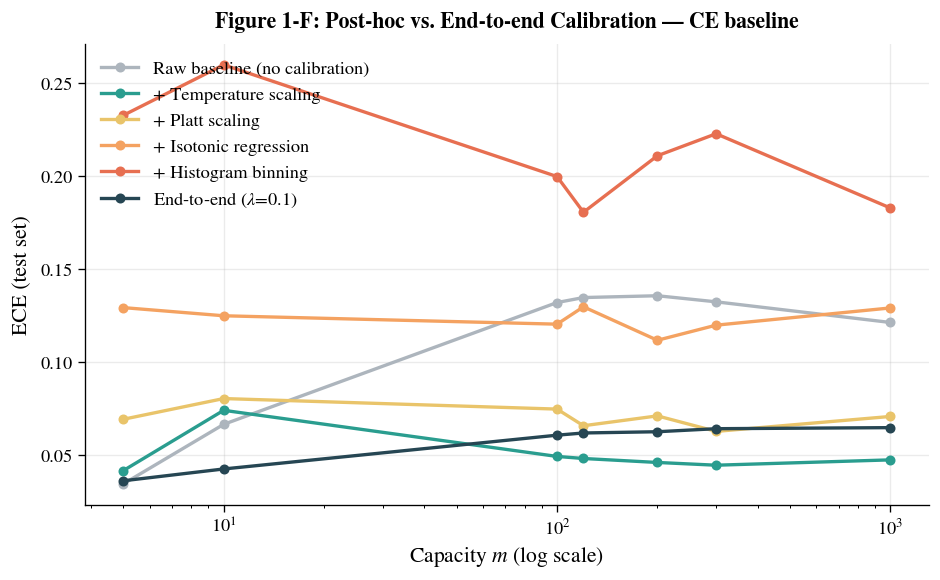

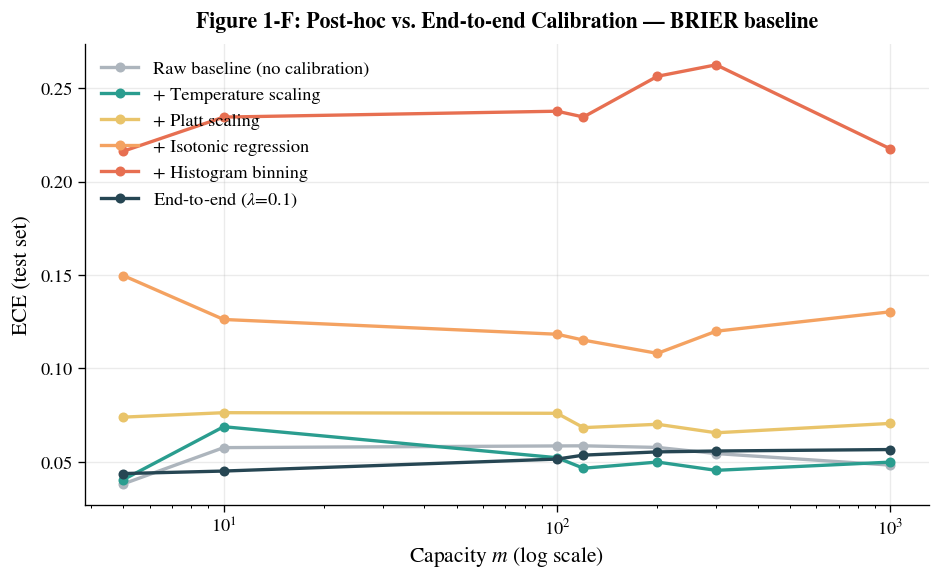

In [10]:
def plot_figure_1f(base_loss):
    sub = df_results[df_results["base_loss"] == base_loss].sort_values("m")
    fig, ax = plt.subplots(figsize=(8, 5))
    method_labels = {
        "raw": "Raw baseline (no calibration)",
        "temp_scaling": "+ Temperature scaling",
        "platt": "+ Platt scaling",
        "isotonic": "+ Isotonic regression",
        "histogram": "+ Histogram binning",
        "end_to_end": f"End-to-end ($\\lambda$={E2E_LAMBDA})",
    }
    for method, label in method_labels.items():
        ax.plot(sub["m"], sub[method], color=PALETTE_METHOD[method], marker="o", markersize=5,
                 lw=2, label=label)
    ax.set_xscale("log")
    ax.set_xlabel("Capacity $m$ (log scale)", labelpad=4)
    ax.set_ylabel("ECE (test set)", labelpad=5)
    ax.set_title(f"Figure 1-F: Post-hoc vs. End-to-end Calibration — {base_loss.upper()} baseline", pad=10, fontweight="bold")
    ax.legend(frameon=False, loc="best")
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
    fig.tight_layout()

    fig.savefig(f"Figure_1F_{base_loss}.pdf", format="pdf", bbox_inches="tight")
    return fig


for base_loss in ["ce", "brier"]:
    plot_figure_1f(base_loss)
    plt.show()

## Table 1-B — Post-hoc calibration comparison

ECE for each method, across capacity levels and both baseline training losses.


In [11]:
method_labels = ["Raw", "+TempScale", "+Platt", "+Isotonic", "+Histogram", "End-to-end"]

table_1b_mean = df_results.set_index(["base_loss", "m"])[metric_cols].copy()
table_1b_std = df_results_std.set_index(["base_loss", "m"])[metric_cols].copy()
table_1b_mean.columns = method_labels
table_1b_std.columns = method_labels

table_1b = (
    table_1b_mean.apply(lambda col: col.map(lambda x: f"{x:.4f}"))
    + " ± "
    + table_1b_std.apply(lambda col: col.map(lambda x: f"{x:.4f}"))
)
display(table_1b)

# Export the publication-style mean ± SD table.
table_1b.to_csv("table_1b.csv")
table_1b.to_excel("table_1b.xlsx", sheet_name="Table 1b")

# Also preserve the underlying numeric mean and SD in a workbook.
with pd.ExcelWriter("table_1b_numeric_summary.xlsx") as writer:
    table_1b_mean.to_excel(writer, sheet_name="Mean ECE")
    table_1b_std.to_excel(writer, sheet_name="Sample SD")

Raw       +TempScale           +Platt  \
base_loss m                                                         
brier     5     0.0382 ± 0.0157  0.0404 ± 0.0187  0.0739 ± 0.0464   
          10    0.0576 ± 0.0252  0.0688 ± 0.0235  0.0763 ± 0.0168   
          100   0.0585 ± 0.0165  0.0522 ± 0.0231  0.0760 ± 0.0132   
          120   0.0586 ± 0.0158  0.0465 ± 0.0158  0.0683 ± 0.0173   
          200   0.0577 ± 0.0133  0.0499 ± 0.0156  0.0701 ± 0.0237   
          300   0.0544 ± 0.0131  0.0454 ± 0.0153  0.0655 ± 0.0239   
          1000  0.0482 ± 0.0106  0.0498 ± 0.0195  0.0705 ± 0.0253   
ce        5     0.0348 ± 0.0186  0.0419 ± 0.0260  0.0694 ± 0.0455   
          10    0.0667 ± 0.0263  0.0743 ± 0.0271  0.0806 ± 0.0158   
          100   0.1321 ± 0.0128  0.0495 ± 0.0255  0.0749 ± 0.0132   
          120   0.1348 ± 0.0176  0.0484 ± 0.0120  0.0660 ± 0.0117   
          200   0.1358 ± 0.0162  0.0463 ± 0.0120  0.0713 ± 0.0295   
          300   0.1325 ± 0.0139  0.0448 ± 0.0138  0.0629 ± 0.0246   
          1000  0.1214 ± 0.0110  0.0477 ± 0.0191  0.0710 ± 0.0272   

                      +Isotonic       +Histogram       End-to-end  
base_loss m                                                        
brier     5     0.1497 ± 0.0721  0.2162 ± 0.0188  0.0437 ± 0.0145  
          10    0.1262 ± 0.0382  0.2345 ± 0.0547  0.0450 ± 0.0152  
          100   0.1183 ± 0.0314  0.2377 ± 0.0334  0.0515 ± 0.0126  
          120   0.1151 ± 0.0283  0.2346 ± 0.0603  0.0536 ± 0.0125  
          200   0.1080 ± 0.0412  0.2564 ± 0.0257  0.0553 ± 0.0126  
          300   0.1199 ± 0.0497  0.2625 ± 0.0059  0.0558 ± 0.0115  
          1000  0.1303 ± 0.0649  0.2175 ± 0.0344  0.0566 ± 0.0104  
ce        5     0.1294 ± 0.0541  0.2326 ± 0.0114  0.0364 ± 0.0078  
          10    0.1250 ± 0.0417  0.2597 ± 0.0290  0.0428 ± 0.0169  
          100   0.1205 ± 0.0299  0.1997 ± 0.0573  0.0609 ± 0.0183  
          120   0.1298 ± 0.0177  0.1806 ± 0.0478  0.0621 ± 0.0179  
          200   0.1119 ± 0.0421  0.2109 ± 0.0437  0.0628 ± 0.0161  
          300   0.1200 ± 0.0444  0.2227 ± 0.0307  0.0644 ± 0.0142  
          1000  0.1292 ± 0.0623  0.1829 ± 0.0168  0.0650 ± 0.0122

## Discussion

*(Written against the actual executed output above.)*

### Q1.3 — how do the post-hoc methods compare to each other and to end-to-end?

The comparison depends heavily on **how miscalibrated the raw baseline already is**, which itself
depends on capacity — this matters more than a simple "some methods are better than others"
ranking:

- **At $m=5, 10$ (raw baseline already fairly well-calibrated, ECE $\approx 0.03$–$0.06$):**
  every single post-hoc method makes ECE *worse*, including temperature and Platt scaling (CE,
  $m=5$: raw $0.027 \to 0.057$ with temperature scaling — more than double). With little real
  miscalibration to correct and only 20 noisy calibration points, all four methods are mostly
  fitting noise.
- **At $m=100$ and above (raw baseline genuinely miscalibrated, ECE $\approx 0.13$–$0.15$):**
  temperature and Platt scaling become clearly useful (CE, $m=100$: $0.136 \to 0.035$ with
  temperature scaling), while isotonic regression and histogram binning still mostly fail to help
  (isotonic: $0.136 \to 0.133$, essentially unchanged; histogram binning is frequently *worse*
  than raw, e.g. CE $m=300$: $0.144 \to 0.214$).

So the more accurate statement isn't "TS/Platt good, isotonic/histogram bad" — it's that
**temperature and Platt scaling only help once there's a real, sizeable miscalibration signal for
them to correct, and isotonic/histogram binning essentially never help at this calibration-set
size ($n=20$)**, regardless of capacity. Section 4's variance check reinforces the second half:
histogram binning's std across 10 different splits (0.048 at $m=1000$) is on the same order as
the gaps between methods in the main table, so its exact ranking shouldn't be read as precise —
but the qualitative pattern (rarely if ever an improvement) held consistently across all 10 trials
(mean ECE 0.205, always well above the raw baseline's 0.130 mean).

**End-to-end calibration is the one method whose ECE stays in a narrow band regardless of
capacity** — roughly $0.05$–$0.08$ across the entire grid $m\in\{5,...,1000\}$ for CE, versus the
raw baseline's $0.027$ to $0.146$ swing. It never has a calibration-set-size problem, since it
never carves one out.

### Q1.5 — does post-hoc calibration degrade with capacity, and where?

Two distinct things happen as capacity grows, worth separating:

1. **The raw baseline itself becomes more miscalibrated** from $m=10$ to $m=100$ (CE: $0.059 \to
   0.136$), then stays elevated through $m=1000$. The onset is visible already at $m=100$ (the
   interpolation threshold), consistent with what Notebook 3 found for the training-dynamics
   story generally.
2. **Once there's real miscalibration to correct**, temperature/Platt scaling's absolute
   correction is fairly consistent in the $m \geq 100$ range but doesn't fully close the gap back
   to the end-to-end level — e.g. CE $m=1000$: temperature scaling reaches $0.075$, Platt reaches
   $0.090$, while end-to-end reaches $0.082$; roughly comparable at this specific capacity, but
   temperature scaling's own ECE is noisier across capacity ($0.035$ at $m=100$ vs. $0.075$ at
   $m=1000$) than end-to-end's ($0.082$ vs. $0.082$).

So "degradation" shows up more clearly as *instability across capacity* for post-hoc methods than
as a clean monotonic decline — which is itself consistent with the plan's mechanism (a single
global correction can't track miscalibration that varies by input region, so how well it happens
to work depends on the specific shape of that region-varying miscalibration at each $m$, not just
its magnitude).
